# Parte 6 (opcional, 2 puntos extra): ¿Le gana una regresión logística al BG/NBD?

En la Parte 4 vimos que el BG/NBD no ordena a los clientes mucho mejor que la recencia sola.
Si lo que queremos es $\mathbb{P}(Z=1)$, ¿para qué tanto esfuerzo con estos modelos?

Una regresión logística con $x$, $t_x$ y $T$ como predictores es la respuesta obvia de cualquier
científico de datos. Aquí la ponemos a competir y después revisamos si la competencia fue justa.

## 6.1 La comparación ingenua

Ajustamos una regresión logística de $Z_i$ contra $x$, $t_x$ y $T$ (estandarizados, sin penalización),
la evaluamos con validación cruzada estratificada de 5 *folds* **sobre clientes**, repetida con 20 semillas,
y la comparamos contra el $\mathbb{P}(Z=1)$ del BG/NBD del inciso 4.3 en AUC, *Brier score* y curva de calibración.

In [1]:
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss

from src.data_prep import cargar_transacciones, construir_resumen

# Colores: una serie = un color fijo, el mismo en todas las graficas
C_BG, C_LOG, C_GRIS = "#2563eb", "#ea580c", "#9ca3af"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "font.size": 10,
})

In [2]:
df = cargar_transacciones("../data/raw/CDNOW_sample.txt")
res = construir_resumen(df)                 # x, t_x, T (calibracion) y x_star (holdout)
res["Z"] = (res["x_star"] >= 1).astype(int)

TAU = 39.0                                  # semanas de holdout: 1997-10-01 a 1998-06-30

print(f"Clientes      : {len(res)}")
print(f"Tasa base P(Z=1): {res.Z.mean():.4f}")
print(f"Rango de T    : {res['T'].min():.1f} a {res['T'].max():.1f} semanas")

Clientes      : 2357
Tasa base P(Z=1): 0.2902
Rango de T    : 27.0 a 38.9 semanas


### El competidor: $\mathbb{P}(Z=1)$ del BG/NBD

Del inciso 4.3, con $\tau = 39$ semanas de *holdout*:

$$\mathbb{P}(Z=1 \mid x,t_x,T) = \mathbb{P}(\text{vivo} \mid x,t_x,T)\left[1-\left(\frac{\alpha+T}{\alpha+T+\tau}\right)^{r+x}\right]$$

In [3]:
R, ALPHA, A, B = 0.243, 4.414, 0.793, 2.426     # estimados de la Parte 2

def p_vivo(x, t_x, T, r=R, alpha=ALPHA, a=A, b=B):
    x, t_x, T = map(lambda v: np.asarray(v, float), (x, t_x, T))
    termino = np.where(x > 0,
                       a / (b + np.maximum(x, 1) - 1) * ((alpha + T) / (alpha + t_x)) ** (r + x),
                       0.0)
    return 1 / (1 + termino)

def p_z1(x, t_x, T, tau, r=R, alpha=ALPHA, a=A, b=B):
    x, T = np.asarray(x, float), np.asarray(T, float)
    return p_vivo(x, t_x, T, r, alpha, a, b) * (1 - ((alpha + T) / (alpha + T + tau)) ** (r + x))

res["p_bg"] = p_z1(res.x, res.t_x, res["T"], TAU)

y = res.Z.values
X = res[["x", "t_x", "T"]].values

In [4]:
# Logistica: 5 folds estratificados sobre clientes, repetidos con 20 semillas.
# Las probabilidades son out-of-fold: ningun cliente se evalua con un modelo que lo vio.
aucs, briers = [], []
oof_semillas = np.zeros((20, len(y)))

for semilla in range(20):
    modelo = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000))
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
    oof = cross_val_predict(modelo, X, y, cv=cv, method="predict_proba")[:, 1]
    oof_semillas[semilla] = oof
    aucs.append(roc_auc_score(y, oof))
    briers.append(brier_score_loss(y, oof))

aucs, briers = np.array(aucs), np.array(briers)
res["p_log"] = oof_semillas.mean(axis=0)        # promedio sobre las 20 semillas

print(f"AUC   : {aucs.mean():.4f} +/- {aucs.std(ddof=1):.4f}   (min {aucs.min():.4f}, max {aucs.max():.4f})")
print(f"Brier : {briers.mean():.4f} +/- {briers.std(ddof=1):.4f}")
print("\nLa variacion entre semillas es minima: el resultado no depende de como caigan los folds.")

AUC   : 0.7775 +/- 0.0010   (min 0.7748, max 0.7790)
Brier : 0.1561 +/- 0.0002

La variacion entre semillas es minima: el resultado no depende de como caigan los folds.


In [5]:
tabla = pd.DataFrame([
    ("BG/NBD  P(Z=1)",        roc_auc_score(y, res.p_bg),  brier_score_loss(y, res.p_bg),  res.p_bg.mean()),
    ("Logistica (out-of-fold)", roc_auc_score(y, res.p_log), brier_score_loss(y, res.p_log), res.p_log.mean()),
    ("Recencia t_x sola",     roc_auc_score(y, res.t_x),   np.nan,                          np.nan),
    ("Frecuencia x sola",     roc_auc_score(y, res.x),     np.nan,                          np.nan),
    ("Predecir la tasa base", np.nan,  brier_score_loss(y, np.full(len(y), y.mean())),      y.mean()),
], columns=["Modelo", "AUC", "Brier", "Prob. media predicha"])

print(f"Tasa real de compra en el holdout: {y.mean():.4f}\n")
print(tabla.to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4f}"))

Tasa real de compra en el holdout: 0.2902

                 Modelo    AUC  Brier  Prob. media predicha
         BG/NBD  P(Z=1) 0.7569 0.1612                0.2619
Logistica (out-of-fold) 0.7776 0.1561                0.2903
      Recencia t_x sola 0.7632      -                     -
      Frecuencia x sola 0.7576      -                     -
  Predecir la tasa base      - 0.2060                0.2902


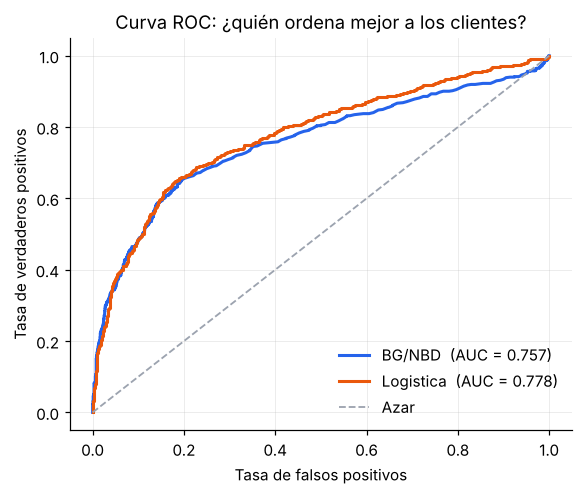

In [6]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))

for nombre, p, color in [("BG/NBD", res.p_bg, C_BG), ("Logistica", res.p_log, C_LOG)]:
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{nombre}  (AUC = {roc_auc_score(y, p):.3f})")

ax.plot([0, 1], [0, 1], "--", color=C_GRIS, lw=1.2, label="Azar")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curva ROC: ¿quién ordena mejor a los clientes?")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

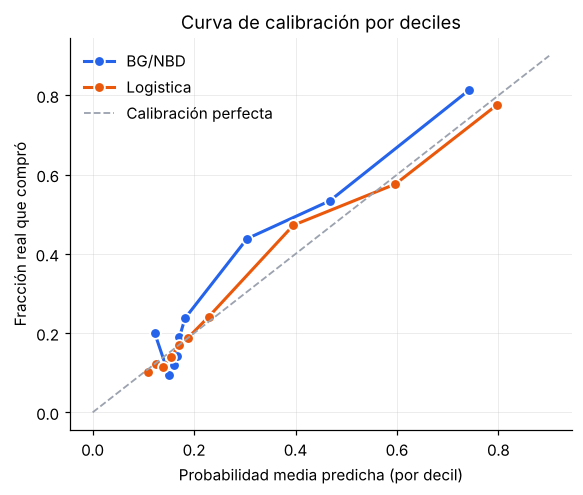

In [7]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))

for nombre, p, color in [("BG/NBD", res.p_bg.values, C_BG), ("Logistica", res.p_log.values, C_LOG)]:
    decil = pd.qcut(p, 10, labels=False, duplicates="drop")
    t = pd.DataFrame({"p": p, "y": y, "d": decil}).groupby("d").agg(pred=("p", "mean"), real=("y", "mean"))
    ax.plot(t.pred, t.real, "o-", color=color, lw=2, ms=7, label=nombre,
            markeredgecolor="white", markeredgewidth=1.2)

ax.plot([0, 0.9], [0, 0.9], "--", color=C_GRIS, lw=1.2, label="Calibración perfecta")
ax.set_xlabel("Probabilidad media predicha (por decil)")
ax.set_ylabel("Fracción real que compró")
ax.set_title("Curva de calibración por deciles")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

In [8]:
# Tabla de calibracion, por si el grafico no basta
for nombre, p in [("BG/NBD", res.p_bg.values), ("Logistica", res.p_log.values)]:
    decil = pd.qcut(p, 10, labels=False, duplicates="drop")
    t = (pd.DataFrame({"p": p, "y": y, "d": decil}).groupby("d")
         .agg(predicho=("p", "mean"), real=("y", "mean"), n=("y", "size")))
    print(f"--- {nombre} ---")
    print(t.round(3).to_string(), "\n")

--- BG/NBD ---
   predicho   real    n
d                      
0     0.123  0.199  241
1     0.150  0.095  231
2     0.155  0.137  241
3     0.160  0.121  240
4     0.166  0.142  246
5     0.171  0.190  232
6     0.182  0.237  219
7     0.304  0.438  235
8     0.467  0.534  236
9     0.742  0.814  236 

--- Logistica ---
   predicho   real    n
d                      
0     0.109  0.102  236
1     0.124  0.123  236
2     0.139  0.115  235
3     0.154  0.140  236
4     0.171  0.169  236
5     0.187  0.187  235
6     0.229  0.242  236
7     0.396  0.472  235
8     0.597  0.576  236
9     0.796  0.775  236 



In [9]:
modelo = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000)).fit(X, y)
lr = modelo.named_steps["logisticregression"]

print("Coeficientes estandarizados (una desviacion estandar de cada variable):")
for nombre, c in sorted(zip(["x", "t_x", "T"], lr.coef_[0]), key=lambda p: -abs(p[1])):
    print(f"  {nombre:4s} {c:+.4f}")
print(f"  intercepto {lr.intercept_[0]:+.4f}")

print("\nCorrelaciones entre predictores:")
print(res[["x", "t_x", "T"]].corr().round(3).to_string())

Coeficientes estandarizados (una desviacion estandar de cada variable):
  t_x  +0.7952
  x    +0.4646
  T    -0.2312
  intercepto -1.0349

Correlaciones entre predictores:
         x    t_x      T
x    1.000  0.663  0.046
t_x  0.663  1.000  0.069
T    0.046  0.069  1.000


### ¿Quién gana?

**La logística, en las dos métricas, pero por muy poco.**

| Modelo | AUC | Brier |
|---|---|---|
| BG/NBD $\mathbb{P}(Z=1)$ | 0.757 | 0.161 |
| **Logística** (out-of-fold) | **0.778** | **0.156** |
| Recencia $t_x$ sola | 0.763 | — |
| Frecuencia $x$ sola | 0.758 | — |
| Predecir la tasa base para todos | — | 0.206 |

La ventaja es de ~0.02 de AUC y ~0.005 de Brier, y es estable: entre las 20 semillas el AUC se mueve
apenas entre 0.775 y 0.779, así que no es ruido de cómo cayeron los *folds*.

El dato incómodo es otro: **la recencia sola (0.763) ya le gana al BG/NBD (0.757)**. Para *ordenar* clientes,
las tres variables crudas contienen prácticamente toda la señal, y el modelo probabilístico no agrega nada.
Esto confirma lo de la Parte 4.

**Donde sí hay una diferencia real es en la calibración.** El BG/NBD subestima de forma sistemática:
predice 0.262 en promedio contra una tasa real de 0.290, y en el decil más alto predice 0.742 cuando
la realidad es 0.814. Los siete deciles de abajo quedan aplastados en una banda estrecha (0.12 a 0.18),
porque todos los clientes con $x = 0$ reciben casi la misma probabilidad.

La logística queda casi encima de la diagonal: su probabilidad media (0.290) coincide con la tasa real
hasta el cuarto decimal. Eso **no es mérito del modelo, es mecánico**: la regresión logística minimiza la
log-pérdida sobre estas mismas etiquetas, y una de sus propiedades es que el promedio de las
probabilidades ajustadas iguala la tasa observada. Dicho de otra forma, está calibrada *para esta ventana*
porque esta ventana es la que vio. Volvemos a esto en 6.2.

### Los coeficientes

Estandarizados (el efecto de moverse una desviación estándar en cada variable):

| Variable | Coeficiente | Lectura |
|---|---|---|
| $t_x$ | **+0.795** | el que más pesa |
| $x$ | +0.465 | un poco más de la mitad que $t_x$ |
| $T$ | −0.231 | el único con signo negativo |
| intercepto | −1.035 | |

- **$t_x$ (+, el más fuerte).** Entre más tarde ocurrió la última compra, más probable es que el cliente
  vuelva a comprar. Es la recencia, y encaja con que sea el mejor predictor individual (AUC 0.763).

- **$x$ (+).** Más compras repetidas en calibración, más probable que compre en el *holdout*. Pesa menos de lo
  que uno esperaría, pero hay que leerlo junto con la correlación: $x$ y $t_x$ están correlacionadas 0.66
  (quien compra mucho casi siempre compró hace poco), así que se reparten el crédito de una misma señal.

- **$T$ (−).** Es el interesante. Controlando por $x$ y $t_x$, un cliente que lleva más tiempo en la base
  tiene un hueco final más largo ($T - t_x$) sin comprar, y eso lo hace ver muerto. La logística está
  reconstruyendo, de forma burda y lineal, la misma idea que en el BG/NBD lleva el cociente
  $\left(\frac{\alpha+T}{\alpha+t_x}\right)^{r+x}$ dentro de $\mathbb{P}(\text{vivo})$.

Los signos son los correctos y la historia es coherente. Pero son tres números fijos ajustados a una ventana
de 39 semanas: no hay nada en ellos que diga qué pasa si la pregunta cambia (6.4), ni de dónde salieron las
etiquetas (6.2).

## 6.2 ¿Fue justa?

**No.** Los dos modelos no vieron la misma información.

### Qué vio cada uno

| | Datos para estimar | ¿Vio el *holdout*? |
|---|---|---|
| **BG/NBD** | transacciones hasta el 30-sep-1997 | **No.** Los parámetros $(r,\alpha,a,b)$ salen solo de la verosimilitud de calibración. Nada posterior al corte. |
| **Logística** | $(x, t_x, T)$ hasta el 30-sep-1997 **+ la etiqueta $Z_i$** | **Sí.** $Z_i$ es "¿compró entre el 1-oct-1997 y el 30-jun-1998?" |

El problema no es que la logística haga trampa con el cliente que evalúa — la validación cruzada
se encarga de eso. El problema es más sutil: **la CV separa clientes, no tiempo.**

En cada *fold*, la logística aprende con $Z_i$ de 4/5 de los clientes, y esas etiquetas describen
el periodo octubre 1997 – junio 1998. Es decir, el modelo ya sabe *cómo se comportó la cohorte en el
periodo que se le está pidiendo pronosticar*: que el 29% compró, que la relación entre recencia y recompra
fue de tal magnitud en esa ventana concreta. El BG/NBD, parado el 30 de septiembre de 1997, no podía saber
nada de eso.

De ahí viene la calibración perfecta de 6.1. No es que la logística modele mejor a los clientes: es que
le dijimos la respuesta agregada.

### ¿Con qué etiquetas podrían haber entrenado en la vida real?

El 30 de septiembre de 1997, las únicas etiquetas disponibles son **de un periodo anterior**. Habría que
partir la calibración en dos:

```
|<---- construir (x, t_x, T) ---->|<---- observar la etiqueta ---->|<---- holdout real ---->|
1-ene-1997                   1-jul-1997                      30-sep-1997              30-jun-1998
```

Features con los datos hasta una fecha de corte anterior, etiqueta = "¿compró entre esa fecha de corte y
el 30 de septiembre?", y recién entonces aplicar el modelo entrenado a los $(x, t_x, T)$ del 30 de septiembre.
Eso es exactamente lo que construimos en **6.3**.

### Relación con la fuga de la tarea de series de tiempo

Es el mismo error con otro disfraz: **usar información que en el momento de pronosticar todavía no existía**
(*look-ahead bias*).

En la tarea de series de tiempo la fuga aparecía al estandarizar la serie completa, o al escoger el modelo
mirando el periodo de prueba, antes de partir en entrenamiento y prueba — el modelo "sabía" algo del futuro
sin que se notara en el código. Aquí la fuga no está en el preprocesamiento sino **en la etiqueta misma**:
$Z_i$ *es* el futuro.

Y es más difícil de ver, porque todo parece correcto: hay validación cruzada, hay estratificación, hay
20 semillas, las probabilidades son *out-of-fold*. Toda esa maquinaria protege contra sobreajustarse a
clientes individuales, y ninguna protege contra la fuga temporal. Un *split* que mezcla clientes de un
mismo periodo nunca puede detectarla; hace falta un *split* por tiempo.

Hay una consecuencia práctica que cierra el punto. Los coeficientes de 6.1 están pegados a una ventana de
39 semanas: el $-0.231$ de $T$ solo tiene sentido para ese horizonte. Si el gerente mañana pregunta por
13 semanas en lugar de 39, el BG/NBD solo cambia $\tau$ en la fórmula y sigue funcionando — nunca necesitó
etiquetas. La logística tendría que volver a entrenarse, y para eso necesita etiquetas que, en el momento de
decidir, no existen. Eso es 6.4.